# __Project Name__ - Car Price Prediction with Machine Learning

##### __Project Type__ - ML/EDA/Regression/Visualization/Model Development/Model Evaluation/Model Refinement
#### __Contribution__ - Individual
SUDHANSHU SHEKHAR

# Project Summary -

The dataset was donated by Jeffrey C. Schlimmer to machine learning archives (https://archive.ics.uci.edu/dataset/10/automobile) on 19 May 1987.
This data set consists of three types of entities: (a) the specification of an auto in terms of various characteristics, (b) its assigned insurance risk rating, (c) its normalized losses in use as compared to other cars. The second rating corresponds to the
degree to which the auto is more risky than its price indicates. Cars are initially assigned a risk factor symbol associated with its price. Then, if it is more risky (or less), this symbol is adjusted by moving it up (or down) the scale. Actuarians call this
process "symboling". A value of +3 indicates that the auto is risky, -3 that it is probably pretty safe.

The third factor is the relative average loss payment per insured vehicle year. This value is normalized for all autos within a
particular size classification (two-door small, station wagons, sports/speciality, etc…), and represents the average loss per car
per year.

It contains over 205 observation and has 26 different attributes is a mixture of categorical and numerical values. Explore and analyze the data to try to predict the price of the car based on the features the car has.

## __Business Objective__ -

The customer wants to know that if they are charged fair price based on the features provided in the car.

# __Problem Statement__ -

Analyze and build a ML model that is able to predict the car price in terms of other car features. This includes the following objectives:
- Determine the variables on which 'price' is dependent on.
- Build a model to predict price using these variables and make some predictions.
- Build multiple models and find the percentage of error for each of them.
- Evaluate each model and find the most optimal one with the least percentage of error.
- Refine the model to minimize the error.

### Install the libraries

In [1]:
try:
    %pip install pandas numpy kagglehub scipy matplotlib seaborn
except:
    print("Unable to install libraries")
finally:
    print("Done")

Note: you may need to restart the kernel to use updated packages.
Done



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import warnings
warnings.filterwarnings("ignore", category = FutureWarning)

### Importing the Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Download the Data

In [65]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("faheem113141/automobiles-price-data")

print("Path to dataset files:", path)

# list the files in the download directory
print("Files in the download directory:", os.listdir(path))

Path to dataset files: C:\Users\shsud\.cache\kagglehub\datasets\faheem113141\automobiles-price-data\versions\1
Files in the download directory: ['imports_85_data.csv']


### Importing the Data

In [66]:
csv_path = os.path.join(path, 'imports_85_data.csv')
df = pd.read_csv(csv_path, header=None)

df.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,column_a,column_b,column_c,column_d,column_e,column_f,column_g,column_h,column_i,column_j,...,column_q,column_r,column_s,column_t,column_u,column_v,column_w,column_x,column_y,column_z
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
2,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,16500
3,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.50,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
4,2,164,audi,gas,std,four,sedan,fwd,front,99.80,...,109,mpfi,3.19,3.40,10.00,102,5500,24,30,13950


### Add Custom headers

In [67]:
# Remove first row
df = df.drop(df.index[0])

# Add custome headers
headers = ["symboling","normalized-losses","make","fuel-type","aspiration", "num-of-doors","body-style",
         "drive-wheels","engine-location","wheel-base", "length","width","height","curb-weight","engine-type",
         "num-of-cylinders", "engine-size","fuel-system","bore","stroke","compression-ratio","horsepower",
         "peak-rpm","city-mpg","highway-mpg","price"]

df.columns = headers

df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
2,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,16500
3,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.50,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
4,2,164,audi,gas,std,four,sedan,fwd,front,99.80,...,109,mpfi,3.19,3.40,10.00,102,5500,24,30,13950
5,2,164,audi,gas,std,four,sedan,4wd,front,99.40,...,136,mpfi,3.19,3.40,8.00,115,5500,18,22,17450


### Dataset Inspection

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 1 to 205
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   symboling          205 non-null    str  
 1   normalized-losses  164 non-null    str  
 2   make               205 non-null    str  
 3   fuel-type          205 non-null    str  
 4   aspiration         205 non-null    str  
 5   num-of-doors       205 non-null    str  
 6   body-style         205 non-null    str  
 7   drive-wheels       205 non-null    str  
 8   engine-location    205 non-null    str  
 9   wheel-base         205 non-null    str  
 10  length             205 non-null    str  
 11  width              205 non-null    str  
 12  height             205 non-null    str  
 13  curb-weight        205 non-null    str  
 14  engine-type        205 non-null    str  
 15  num-of-cylinders   205 non-null    str  
 16  engine-size        205 non-null    str  
 17  fuel-system        205 non-

We can see that some of the variables have null values. Lets find out which ones.

#### Inspecting null values

Replace '?' with Nan

In [69]:
df = df.replace('?', np.nan)

In [70]:
df.isnull().sum()[df.isnull().sum() > 0]

normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64

All these variables have null values. Note that none of them are a lot in numbers so we don't need to drop the column. However since there are 4 rows without the 'price' which would cause problem as it is our target variable. So we will need to remove those rows.

#### Inspecting the data types

In [71]:
df.dtypes

symboling            str
normalized-losses    str
make                 str
fuel-type            str
aspiration           str
num-of-doors         str
body-style           str
drive-wheels         str
engine-location      str
wheel-base           str
length               str
width                str
height               str
curb-weight          str
engine-type          str
num-of-cylinders     str
engine-size          str
fuel-system          str
bore                 str
stroke               str
compression-ratio    str
horsepower           str
peak-rpm             str
city-mpg             str
highway-mpg          str
price                str
dtype: object

Here we see all the columns are of 'string' type which is incorrect. For analysis purpose we need to format them with correct data types, So that the algorithms and methods we apply can be able to detect their values and won't run into problem.

'symboling' refers to the insurance risk level having values ranging from -3 to +3, so it should be int64.
'normalized-losses' is a continuous numerical variable should be of type int64.
Columns 'bore' and 'stroke' describe the engines they should be of type float64.
Like-wise 'price' which is our target variable should also be of float64.
Similarly the following should be data types of different variables:
- peak-rpm: float64
- horsepower: int64
- highway-mpg: int64
- city-mpg: int64
- compression-ratio: float64
- length, width and height: float64
- curb-widght: int64
- engine-size: int64
- wheel-base: float64

### Data Cleaning

#### Dealing with the Missing values

In [72]:
df.isnull().sum()[df.isnull().sum() > 0]

normalized-losses    41
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
price                 4
dtype: int64

#### Replace by average

Since the null values for each column are not a lot we can replace these null values with the average values of their respective columns.

In [73]:
avg_normalized_losses = df['normalized-losses'].astype(float).mean()
df['normalized-losses'] = df['normalized-losses'].replace(np.nan, avg_normalized_losses)

avg_bore = df['bore'].astype(float).mean()
df['bore'] = df['bore'].replace(np.nan, avg_bore)

avg_stroke = df['stroke'].astype(float).mean()
df['stroke'] =  df['stroke'].replace(np.nan, avg_stroke)

avg_horsepower = df['horsepower'].astype(float).mean()
df['horsepower'] = df['horsepower'].replace(np.nan, avg_horsepower)

avg_peak_rpm = df['peak-rpm'].astype(float).mean()
df['peak-rpm'] = df['peak-rpm'].replace(np.nan, avg_peak_rpm)

#### Replace by most common

Since 'num-of-doors' is a categorical variable it doesn't have an average value. Fot this we replace the missing values with most frequent occuring value.

In [74]:
# Find the most common value in 'num-of-doors'
df['num-of-doors'].value_counts()

num-of-doors
four    114
two      89
Name: count, dtype: int64

In [75]:
# Replacing the missing values with 'four'
df['num-of-doors'] = df['num-of-doors'].replace(np.nan, "four")

Need to drop the rows which do not contain 'price' value.

In [76]:
df = df.dropna(subset=['price'], axis=0)

# reset the index after drop
df = df.reset_index(drop=True)

Now check the number of missing values.

In [77]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

No missing values now.

In [78]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,13495
1,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.60,...,130,mpfi,3.47,2.68,9.00,111,5000,21,27,16500
2,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.50,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.80,...,109,mpfi,3.19,3.40,10.00,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.40,...,136,mpfi,3.19,3.40,8.00,115,5500,18,22,17450


#### Data Fomatting

Setting the correct data types to the variables.

In [79]:
# changing to int
df[['symboling', 'normalized-losses', 'curb-weight', 'engine-size', 'city-mpg', 'highway-mpg']] = df[['symboling', 'normalized-losses', 'curb-weight', 'engine-size', 'city-mpg', 'highway-mpg']].astype(int)

# changing to float
df[['wheel-base', 'length', 'width', 'height', 'bore', 'stroke', 'peak-rpm', 'price']] = df[['wheel-base', 'length', 'width', 'height', 'bore', 'stroke', 'peak-rpm', 'price']].astype(float)

In [80]:
df.dtypes

symboling              int64
normalized-losses      int64
make                     str
fuel-type                str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio        str
horsepower            object
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
dtype: object

#### Dataset Normalization

In [81]:
df[['length', 'width', 'height']].head()

,length,width,height
0,168.8,64.1,48.8
1,168.8,64.1,48.8
2,171.2,65.5,52.4
3,176.6,66.2,54.3
4,176.6,66.4,54.3


In [82]:
for col in df[['length', 'width', 'height']].columns.to_list():
    print(col)
    print('min:', df[col].min())
    print('max:', df[col].max())
    print("")

length
min: 141.1
max: 208.1

width
min: 60.3
max: 72.0

height
min: 47.8
max: 59.8



Column 'width' and 'height' have continous values which are comparable in range while 'length' has continous values in the range 141 to 208. This data is skewed since the values of 'length' is more as compared to 'width' and 'heigh'. It creates a bias towards 'length' for algorithms like Regression. So they need to be brought down to similar range. We divide the current value with the maximum value to make them in the range 0 and 1.

In [83]:
df['length'] = df['length']/df['length'].max()

df['width'] = df['width']/df['width'].max()

df['height'] = df['height']/df['height'].max()

In [84]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,122,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.00,111,5000.0,21,27,13495.0
1,3,122,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.00,111,5000.0,21,27,16500.0
2,1,122,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.00,154,5000.0,19,26,16500.0
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.00,102,5500.0,24,30,13950.0
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.00,115,5500.0,18,22,17450.0


#### Data Binning

For Better understanding of continuous variables like 'horsepower' we would divide it to categories and visualize its distribution along the dataset.

In [85]:
# convert to correct data format
df['horsepower'] = df['horsepower'].astype(int)

# setting up endpoints for the categories
bins = np.linspace(min(df['horsepower']), max(df['horsepower']), 4)

# categories names
group_names = ['low', 'medium', 'high']

df['horsepower-binned'] = pd.cut(df['horsepower'], bins=bins, labels=group_names, include_lowest=True)

df[['horsepower', 'horsepower-binned']].head()

,horsepower,horsepower-binned
0,111,low
1,111,low
2,154,medium
3,102,low
4,115,low


In [86]:
df['horsepower-binned'].value_counts()

horsepower-binned
low       153
medium     43
high        5
Name: count, dtype: int64

Visualize the distribution of 'horsepower' across the three categories

Text(0.5, 1.0, 'horsepower categories')

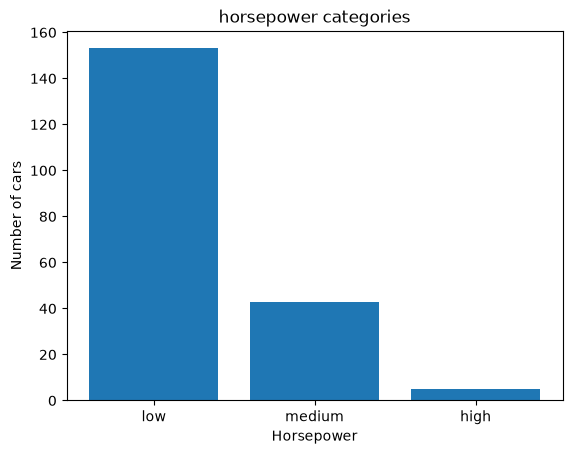

In [87]:
%matplotlib inline
plt.bar(group_names, df['horsepower-binned'].value_counts().reindex(group_names))

plt.xlabel("Horsepower")
plt.ylabel("Number of cars")
plt.title("horsepower categories")

Most of the cars are of low horsepower and very few of the cars have high horse power.

In [88]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,horsepower-binned
0,3,122,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.00,111,5000.0,21,27,13495.0,low
1,3,122,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.00,111,5000.0,21,27,16500.0,low
2,1,122,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,mpfi,2.68,3.47,9.00,154,5000.0,19,26,16500.0,medium
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.00,102,5500.0,24,30,13950.0,low
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.00,115,5500.0,18,22,17450.0,low


In [89]:
print("Unique values of fuel-type:", df['fuel-type'].unique())

Unique values of fuel-type: <StringArray>
['gas', 'diesel']
Length: 2, dtype: str


We have a column like 'fuel-type' which only have two types of values. This is useful while doing analysis as it could help deduce that cars using gas as their fuel type are more expensive the ones using diesel or vice verse.

We would need to convert them to numerical type.

In [90]:
dummy_fuel_types = pd.get_dummies(df['fuel-type'], dtype=int)

In [91]:
dummy_fuel_types.head()

,diesel,gas
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [92]:
dummy_fuel_types.rename(columns={'gas': 'fuel-type-gas',
                                 'diesel': 'fuel-type-diesel'}, inplace=True)

# merge data frames df and dummy_fuel_types
df = pd.concat([df, dummy_fuel_types], axis=1)

# drop the original 'fuel-type' column
df.drop('fuel-type', axis=1, inplace=True)

In [93]:
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,horsepower-binned,fuel-type-diesel,fuel-type-gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,2.68,9.00,111,5000.0,21,27,13495.0,low,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,2.68,9.00,111,5000.0,21,27,16500.0,low,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,3.47,9.00,154,5000.0,19,26,16500.0,medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,3.40,10.00,102,5500.0,24,30,13950.0,low,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,3.40,8.00,115,5500.0,18,22,17450.0,low,0,1


Now the data is cleaned and ready for analysis.

Save the data locally.

In [94]:
df.to_csv('cars_85_cleaned_data.csv', index=False)

### Exploaratory Data Analysis

Load the clean data.

In [95]:
df = pd.read_csv('cars_85_cleaned_data.csv')

df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,horsepower-binned,fuel-type-diesel,fuel-type-gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,2.68,9.0,111,5000.0,21,27,13495.0,low,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,2.68,9.0,111,5000.0,21,27,16500.0,low,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,3.47,9.0,154,5000.0,19,26,16500.0,medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,3.40,10.0,102,5500.0,24,30,13950.0,low,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,3.40,8.0,115,5500.0,18,22,17450.0,low,0,1


Statistics for numerical and categorical variables.

In [97]:
df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,fuel-type-diesel,fuel-type-gas
count,201.000000,201.00000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,122.00000,98.797015,0.837102,0.915126,0.899108,2555.666667,126.875622,3.330692,3.256874,10.164279,103.402985,5117.665368,25.179104,30.686567,13207.129353,0.099502,0.900498
std,1.254802,31.99625,6.066366,0.059213,0.029187,0.040933,517.296727,41.546834,0.268072,0.316048,4.004965,37.365650,478.113805,6.423220,6.815150,7947.066342,0.300083,0.300083
min,-2.000000,65.00000,86.600000,0.678039,0.837500,0.799331,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000,0.000000,0.000000
25%,0.000000,101.00000,94.500000,0.801538,0.890278,0.869565,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,0.000000,1.000000
50%,1.000000,122.00000,97.000000,0.832292,0.909722,0.904682,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5125.369458,24.000000,30.000000,10295.000000,0.000000,1.000000
75%,2.000000,137.00000,102.400000,0.881788,0.925000,0.928094,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,0.000000,1.000000
max,3.000000,256.00000,120.900000,1.000000,1.000000,1.000000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000,1.000000,1.000000


In [99]:
df.describe(include="str")

,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system,horsepower-binned
count,201,201,201,201,201,201,201,201,201,201
unique,22,2,2,5,3,2,6,7,8,3
top,toyota,std,four,sedan,fwd,front,ohc,four,mpfi,low
freq,32,165,115,94,118,198,145,157,92,153


#### Regression

To predict price we would need to analyze the correlation between different variables.

Analyzing the Correlation between different numerical variables.

In [101]:
numeric_df = df.select_dtypes(include=['float', 'int'])

correlation_df = numeric_df.corr()
correlation_df

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,fuel-type-diesel,fuel-type-gas
symboling,1.000000,0.466264,-0.535987,-0.365404,-0.242423,-0.550160,-0.233118,-0.110581,-0.140019,-0.008153,-0.182196,0.075810,0.279740,-0.035527,0.036233,-0.082391,-0.196735,0.196735
normalized-losses,0.466264,1.000000,-0.056661,0.019424,0.086802,-0.373737,0.099404,0.112360,-0.029862,0.055045,-0.114713,0.217300,0.239543,-0.225016,-0.181877,0.133999,-0.101546,0.101546
wheel-base,-0.535987,-0.056661,1.000000,0.876024,0.814507,0.590742,0.782097,0.572027,0.493244,0.158018,0.250313,0.371178,-0.360305,-0.470606,-0.543304,0.584642,0.307237,-0.307237
length,-0.365404,0.019424,0.876024,1.000000,0.857170,0.492063,0.880665,0.685025,0.608971,0.123952,0.159733,0.579795,-0.285970,-0.665192,-0.698142,0.690628,0.211187,-0.211187
width,-0.242423,0.086802,0.814507,0.857170,1.000000,0.306002,0.866201,0.729436,0.544885,0.188822,0.189867,0.615056,-0.245800,-0.633531,-0.680635,0.751265,0.244356,-0.244356
height,-0.550160,-0.373737,0.590742,0.492063,0.306002,1.000000,0.307581,0.074694,0.180449,-0.060663,0.259737,-0.087001,-0.309974,-0.049800,-0.104812,0.135486,0.281578,-0.281578
curb-weight,-0.233118,0.099404,0.782097,0.880665,0.866201,0.307581,1.000000,0.849072,0.644060,0.167438,0.156433,0.757981,-0.279361,-0.749543,-0.794889,0.834415,0.221046,-0.221046
engine-size,-0.110581,0.112360,0.572027,0.685025,0.729436,0.074694,0.849072,1.000000,0.572609,0.205928,0.028889,0.822668,-0.256733,-0.650546,-0.679571,0.872335,0.070779,-0.070779
bore,-0.140019,-0.029862,0.493244,0.608971,0.544885,0.180449,0.644060,0.572609,1.000000,-0.055390,0.001263,0.566903,-0.267392,-0.582027,-0.591309,0.543155,0.054458,-0.054458
stroke,-0.008153,0.055045,0.158018,0.123952,0.188822,-0.060663,0.167438,0.205928,-0.055390,1.000000,0.187871,0.098128,-0.063561,-0.033956,-0.034636,0.082269,0.241064,-0.241064


Here some of the variables have a good correlation with 'price' like 'curb-weight' and 'engine-size'. This indicates that as these variables change how well the target variable 'price' change with it.

We would extract these variables. We are using 0.5 as a good correlation coefficient value for a variable to be potentially be a good predictor.

In [111]:
variables = []

for col, values in correlation_df['price'].items():
    if (col != 'price'):
        if (values > 0.5 or values < -0.5):
            variables.append(col)

print("Numerical variables which can be potential good predictor for price:")
print(variables, end=" ")


Numerical variables which can be potential good predictor for price:
['wheel-base', 'length', 'width', 'curb-weight', 'engine-size', 'bore', 'horsepower', 'city-mpg', 'highway-mpg'] 

#### Regression Analysis

Use regression plots to analyze the extent of their correlation.

Lets analyse for 'engine-size' and 'price'.

(0.0, 53284.93845237676)

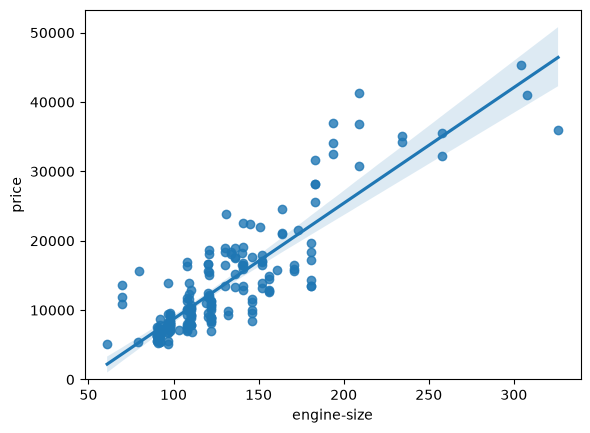

In [109]:
sns.regplot(x = 'engine-size', y = 'price', data = df)
plt.ylim(0,)

As the 'engine-size' increases the 'price' value also increases. This shows a positive correlation between them. Also the slop is steep indicating a strong correlation.

Lets inspect the correlation coefficient value between them.

In [110]:
df[['engine-size', 'price']].corr()

,engine-size,price
engine-size,1.000000,0.872335
price,0.872335,1.000000


A Correlation Coefficient value of 0.872335 indicates 'engine-size' as a potentially strong predictor of 'price'.

Similarly analyse for 'highway-mpg' and 'price'.

(0.0, 48156.909514212995)

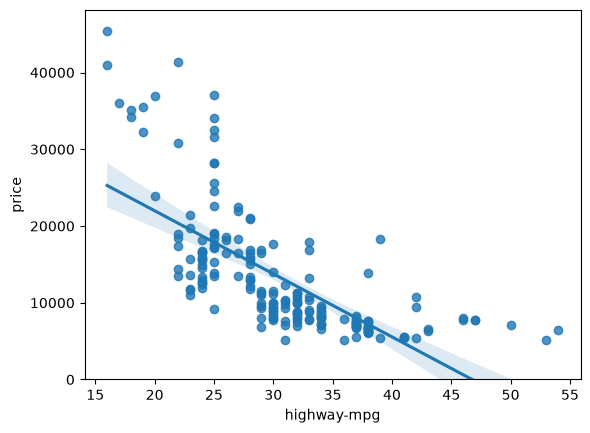

In [112]:
sns.regplot(x = 'highway-mpg', y = 'price', data = df)
plt.ylim(0,)

In [113]:
df[['highway-mpg', 'price']].corr()

,highway-mpg,price
highway-mpg,1.000000,-0.704692
price,-0.704692,1.000000


Gives a negative relationship between the two variables. The correlation coefficient value being at -0.7 makes 'highway-mpg' a potential predictor of 'price'.

Lets analyze a column which we didn't included in the list of our potential good predictors. The 'peak-rpm' variable is not included in our list. Lets analyze its relationship with 'price'.

<Axes: xlabel='peak-rpm', ylabel='price'>

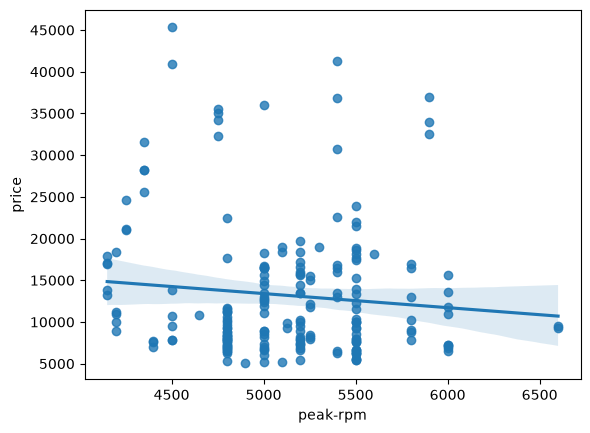

In [114]:
sns.regplot(x = 'peak-rpm', y = 'price', data=df)

The graph isn't steep at all and is almost horizontal. The 'price' values are scattered all over the plot and are too away from the regression line. 'peak-rpm' doesn't seem like a good predictor.

In [115]:
df[['peak-rpm', 'price']].corr()

,peak-rpm,price
peak-rpm,1.000000,-0.101616
price,-0.101616,1.000000


The correlation coefficient value is close to zero. So it is not a good predictor for 'price'. If used in the model would perform very poorly.

To analyze __categorical variables__ we would need to use __box plots__.

In [118]:
df.describe(include='str')

,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,engine-type,num-of-cylinders,fuel-system,horsepower-binned
count,201,201,201,201,201,201,201,201,201,201
unique,22,2,2,5,3,2,6,7,8,3
top,toyota,std,four,sedan,fwd,front,ohc,four,mpfi,low
freq,32,165,115,94,118,198,145,157,92,153


Lets analyze 'body-style' with the 'price'.

<Axes: xlabel='body-style', ylabel='price'>

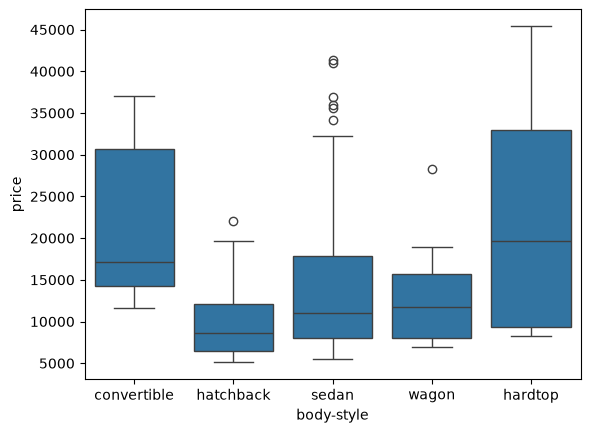

In [117]:
sns.boxplot(x = 'body-style', y = 'price', data=df)

Here we see that the distribution of 'price' between different bodystyle categories have significant overlap, so 'body-style' would not be a good predictor of 'price'.

Examine 'engine-location' and 'price'.

<Axes: xlabel='engine-location', ylabel='price'>

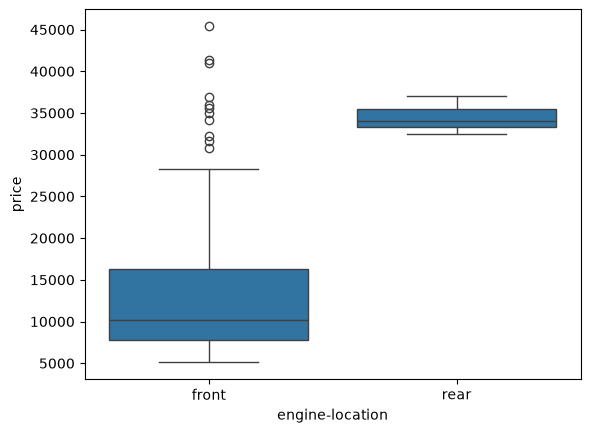

In [119]:
sns.boxplot(x = 'engine-location', y = 'price', data = df)

We see that the distribution of price between their two categories are distinct enough to take 'engine-location' as a potential good predictor for price.

Analyze for 'drive-wheels' and 'price'.

<Axes: xlabel='drive-wheels', ylabel='price'>

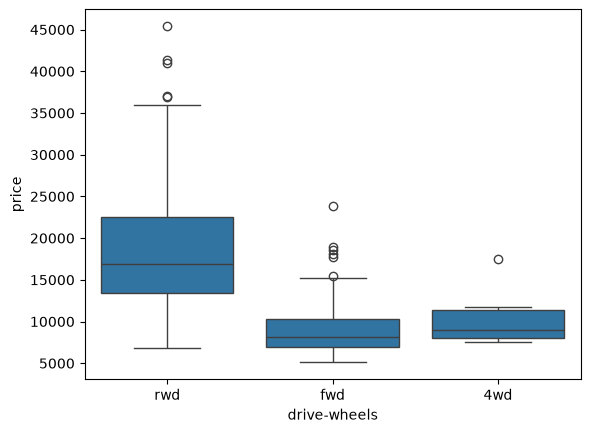

In [120]:
sns.boxplot(x = 'drive-wheels', y = 'price', data = df)

Distribution of price between 'rwd' and other two categories differ. So, drive-wheels could also potentially be a predictor of price.

Analyze for aspiration and price.

<Axes: xlabel='aspiration', ylabel='price'>

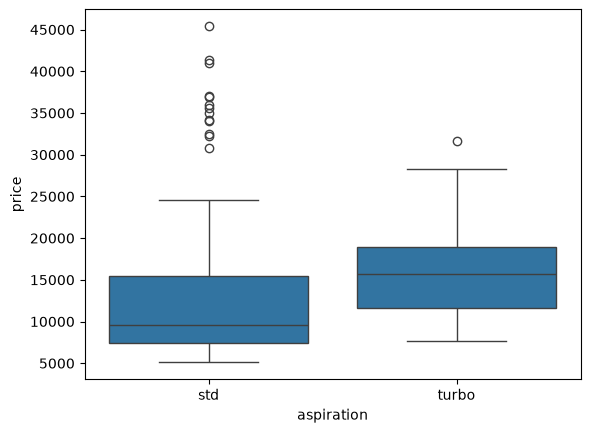

In [121]:
sns.boxplot(x = 'aspiration', y = 'price', data = df)

Have significant overlap between the two categories. So aspiration is not a good predictor for price.

#### Descriptive Statiscal Analysis

So far 'drive-wheels' and 'engine-location' are the two categorical variable who are considered as potential good predictor.

Analyze for any biasness in their values that could lead to wrong result while prediction in the model.

Examine the counts of each categories in their respective variables.

In [124]:
df['drive-wheels'].value_counts().to_frame()

,count
drive-wheels,
fwd,118
rwd,75
4wd,8


They aren't are comparable in their counts 4wd drive is very less but the one which showed diffent result in the boxplot was rwd which is 75 and is comparable to the rest of the values of others. So no biasness in this variable.

Analyze for 'engine-location' and price.

In [125]:
df['engine-location'].value_counts().to_frame()

,count
engine-location,
front,198
rear,3


'engine-location' has only 3 observations with 'rear' value compaired to 198 observations of 'front'. So This data is highly skewed and would result in biasness if used in the model.

So 'engine-location' is not a good predictor for price.

#### Group By Analysis

Analyzing a relationship between group of combination of 'drive-wheels' and 'body-style' with 'price'.

In [127]:
# select the two columns
df_group = df[['drive-wheels', 'body-style', 'price']]
df_group_test = df_group.groupby(['drive-wheels', 'body-style'], as_index=False).agg({'price': 'mean'})
df_group_test

,drive-wheels,body-style,price
0,4wd,hatchback,7603.000000
1,4wd,sedan,12647.333333
2,4wd,wagon,9095.750000
3,fwd,convertible,11595.000000
4,fwd,hardtop,8249.000000
5,fwd,hatchback,8396.387755
6,fwd,sedan,9811.800000
7,fwd,wagon,9997.333333
8,rwd,convertible,23949.600000
9,rwd,hardtop,24202.714286


We can see that cars with rear-wheel-drive and hardtop bodystyle are more expensive and car with four-wheel-drive and hatchback bodystyle are least expensive.

Visualizing this with a __Heat Map__.

In [128]:
grouped_pivot  = df_group_test.pivot(index='drive-wheels', columns='body-style')
grouped_pivot

price                                            \
body-style   convertible       hardtop     hatchback         sedan   
drive-wheels                                                         
4wd                  NaN           NaN   7603.000000  12647.333333   
fwd              11595.0   8249.000000   8396.387755   9811.800000   
rwd              23949.6  24202.714286  14337.777778  21711.833333   

                            
body-style           wagon  
drive-wheels                
4wd            9095.750000  
fwd            9997.333333  
rwd           16994.222222

In [129]:
grouped_pivot = grouped_pivot.replace(np.nan, 0)
grouped_pivot

price                                            \
body-style   convertible       hardtop     hatchback         sedan   
drive-wheels                                                         
4wd                  0.0      0.000000   7603.000000  12647.333333   
fwd              11595.0   8249.000000   8396.387755   9811.800000   
rwd              23949.6  24202.714286  14337.777778  21711.833333   

                            
body-style           wagon  
drive-wheels                
4wd            9095.750000  
fwd            9997.333333  
rwd           16994.222222

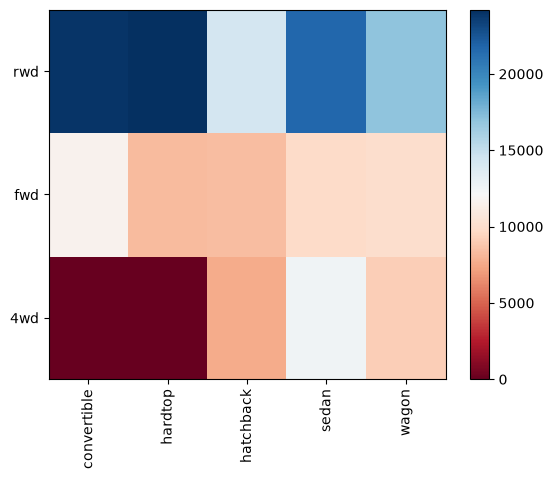

In [130]:
fig, ax = plt.subplots()
im = ax.pcolor(grouped_pivot, cmap='RdBu')

# label names
row_labels = grouped_pivot.columns.levels[1]
col_labels = grouped_pivot.index

# move ticks and labels to the center
ax.set_xticks(np.arange(grouped_pivot.shape[1]) + 0.5, minor=False)
ax.set_yticks(np.arange(grouped_pivot.shape[0]) + 0.5, minor=False)

# insert labels
ax.set_xticklabels(row_labels, minor=False)
ax.set_yticklabels(col_labels, minor=False)

# rotate label if too long
plt.xticks(rotation = 90)

fig.colorbar(im)
plt.show()
 

Cars having rear-wheel-drive and hardtop body style have highest average price. Also cars with rear-wheel-drive and convertible relatively high price.

Also cars with four-wheel-drive and wagon body styel have the lowest average price. Cars having four wheel drive and hatchbacks have relatively low price.

#### Correlation Analysis

We identified the numerical variables which could potentially be used as predictor for price and also find the values of their correlation coefficients.

Now we have to analyze how accurate these coefficients were. For this we would use __Pearson's Correlation__ and __p-value__.
The value of Pearson's correlation quantifies the amount of relationship between two variables and p-value gives the probability or confidence that the corelation between those two variables are statistically significant.

Usually a p-value of 0.05 means 95% confidence that the pearson correlation value calculated is correct and correlation exists between the variables is significant. If the p-value comes out to be less than 0.001 that means its 100% evident that correlation is significant.

In [131]:
predictors = variables
print(predictors, end = " ")

['wheel-base', 'length', 'width', 'curb-weight', 'engine-size', 'bore', 'horsepower', 'city-mpg', 'highway-mpg'] 

Analyse Pearson coefficient and p-value for 'wheel-base' and 'price'.

In [132]:
from scipy.stats import pearsonr

pearson_coef, p_value = pearsonr(df['wheel-base'], df['price'])

print("Pearson coefficient:", pearson_coef)
print("p-value            :", p_value)

Pearson coefficient: 0.584641822265508
p-value            : 8.076488270732847e-20


Since p-value is very less than 0.001, the corelation between wheel-base and price is significant, but the linear relation isn't extremely strong (~0.585). But 'wheel-base' could be used as one of the predictors for price since corelation is still greater than 0.5.

Doing same for the rest of the predictors.

length vs price

In [133]:
pearson_coef, p_value = pearsonr(df['length'], df['price'])

print("Pearson coefficient:", pearson_coef)
print("p-value            :", p_value)

Pearson coefficient: 0.6906283804483639
p-value            : 8.016477466159293e-30


p-value less than 0.001, the corelation between length and price is significant, and the linear relation is moderate (~0.69). Length could be used as a predictor for price.

In [134]:
for i in range(2, len(predictors)):
    variable = predictors[i]
    pearson_coef, p_value = pearsonr(df[variable], df['price'])

    print(variable)
    print("Pearson coefficient:", pearson_coef)
    print("p-value            :", p_value)
    print("")

width
Pearson coefficient: 0.7512653440522675
p-value            : 9.200335510480589e-38

curb-weight
Pearson coefficient: 0.8344145257702844
p-value            : 2.189577238893924e-53

engine-size
Pearson coefficient: 0.8723351674455184
p-value            : 9.26549162219869e-64

bore
Pearson coefficient: 0.5431553832626603
p-value            : 8.049189483935276e-17

horsepower
Pearson coefficient: 0.8096068016571054
p-value            : 6.273536270650361e-48

city-mpg
Pearson coefficient: -0.686571006784468
p-value            : 2.3211320655675065e-29

highway-mpg
Pearson coefficient: -0.7046922650589531
p-value            : 1.749547114447559e-31



Seeing the p-value for the rest of our predictors they all have values less than 0.001. So the correlation between all these variables and price are significant. The correlation values of 'engin-size', 'curb-weight', 'horsepower', 'width' and 'highway-mpg' are highest and close to 1, indicating strong correlation between them and price. The correlation values of 'city-mpg' and 'bore' are moderate (close to 0.5). So relationship between them and price is moderate.

So all these numerical variables can be used as a predictor.

#### Conclusion

The important variables that can be used to predict the car price.

Continous numerical variables:-
- wheel-base
- length
- width
- curb-weight
- engine-size
- bore
- city-mpg
- higway-mpg

Categorical variables:-
- drive-wheels

We have successfully identified the variables which are correlated to our target variable price.

### Model Development